# Movie Data Visualization and Exploratory Data Analysis

## Overview

This notebook presents the visual exploratory data analysis of the cleaned TMDB movie dataset. The objective is to identify important patterns and relationships in movie ratings, revenue, genres, budgets, release trends, actors, runtimes, popularity, vote counts and keywords.

The analysis uses Matplotlib, Seaborn and Plotly to create univariate, bivariate and multivariate visualisations. Each visualisation is followed by a short insight explaining the main finding and its relevance to movie industry analysis.

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import seaborn as sns
import plotly.express as px

movies = pd.read_csv("../data/movies_cleaned_corrected.csv")

print("Movies dataset loaded successfully!")
print("Number of movies:", len(movies))

Movies dataset loaded successfully!
Number of movies: 2503


## Chart 1: Distribution of Movie Ratings

**Analysis Type:** Univariate Analysis

This histogram examines the distribution of average movie ratings across the cleaned TMDB dataset.

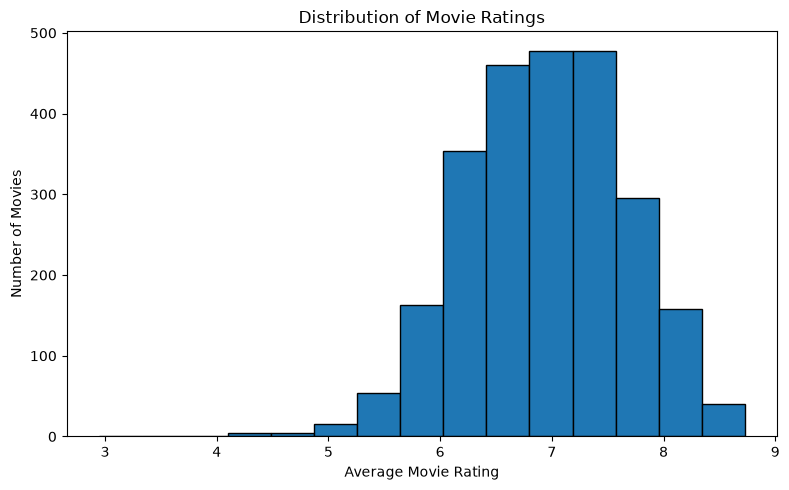

In [4]:
plt.figure(figsize=(8, 5))

plt.hist(
    movies["vote_average"].dropna(),
    bins=15,
    edgecolor="black"
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Average Movie Rating")
plt.ylabel("Number of Movies")
plt.tight_layout()

plt.savefig("../charts/chart_01_rating_distribution.png")
plt.show()

### Insight — Chart 1: Distribution of Movie Ratings

This histogram shows how average movie ratings are distributed across the dataset. It helps identify the rating ranges in which most movies are concentrated and whether very low or very high ratings are less common. The distribution provides an overview of the general audience reception of the movies analysed.

## Chart 2: Top 10 Highest-Grossing Movies

**Analysis Type:** Univariate Analysis

This bar chart compares the worldwide revenue of the ten highest-grossing movies in the cleaned TMDB dataset.

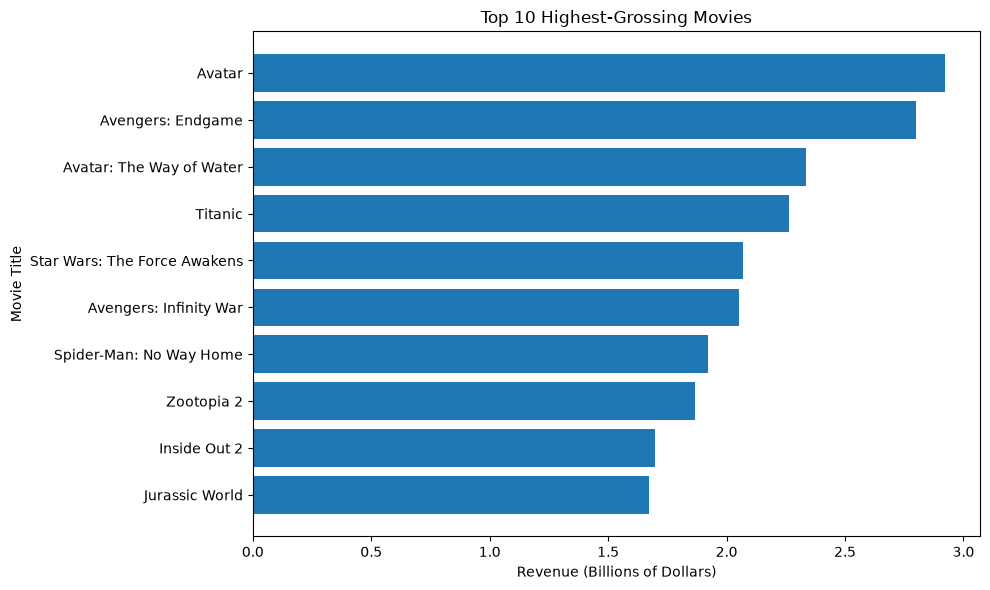

In [5]:
top_revenue = movies.dropna(subset=["revenue"]).nlargest(10, "revenue")

plt.figure(figsize=(10, 6))

plt.barh(
    top_revenue["title"][::-1],
    top_revenue["revenue"][::-1] / 1_000_000_000
)

plt.title("Top 10 Highest-Grossing Movies")
plt.xlabel("Revenue (Billions of Dollars)")
plt.ylabel("Movie Title")
plt.tight_layout()

plt.savefig("../charts/chart_02_top_revenue.png")
plt.show()

### Insight — Chart 2: Top 10 Highest-Grossing Movies

The chart compares the worldwide revenues of the ten highest-grossing movies in the dataset. *Avatar* ranks first, followed by *Avengers: Endgame* and *Avatar: The Way of Water*. The results show that a small group of major blockbuster films generated exceptionally high box-office revenue compared with most movies in the dataset.

## Chart 3: Average Popularity by Movie Genre

**Analysis Type:** Bivariate Analysis

This bar chart compares the average movie popularity across different genres to identify which genres show the strongest audience interest in the dataset.

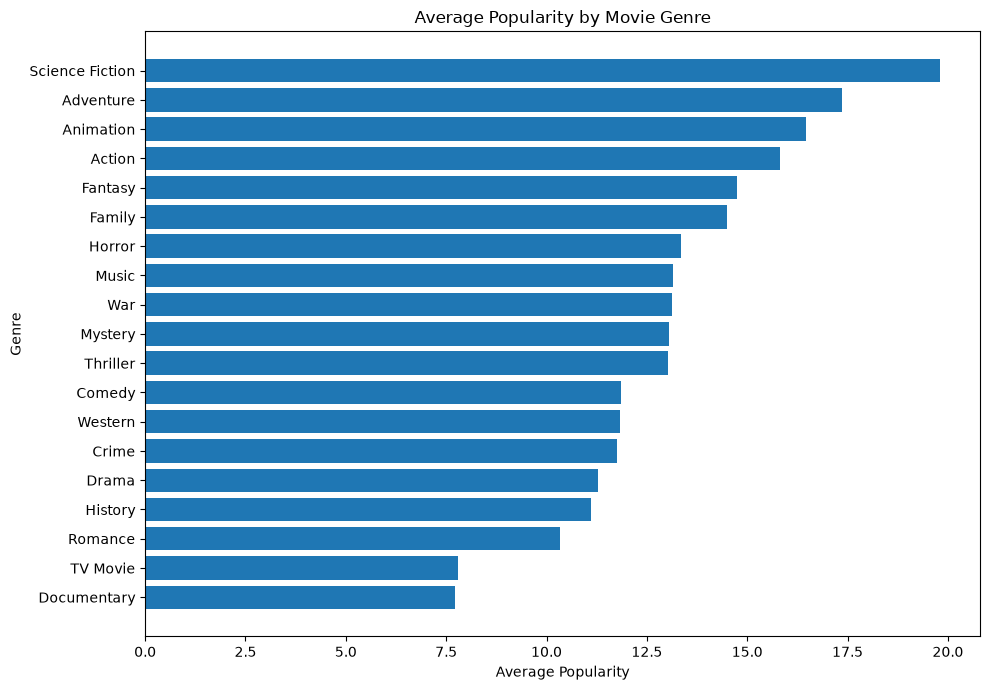

In [6]:
movie_genres = pd.read_csv("../data/movie_genres_cleaned.csv")
genres = pd.read_csv("../data/genres_cleaned.csv")

genre_data = movie_genres.merge(
    genres,
    on="genre_id"
)

genre_data = genre_data.merge(
    movies[["movie_id", "popularity"]],
    on="movie_id"
)

genre_popularity = (
    genre_data.groupby("genre_name")["popularity"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(10, 7))

plt.barh(
    genre_popularity.index,
    genre_popularity.values
)

plt.title("Average Popularity by Movie Genre")
plt.xlabel("Average Popularity")
plt.ylabel("Genre")
plt.tight_layout()

plt.savefig("../charts/chart_03_genre_popularity.png")
plt.show()

### Insight — Chart 3: Average Popularity by Movie Genre

Science Fiction has the highest average popularity score in this dataset, followed by Adventure and Animation. Drama and Romance have lower average popularity scores in comparison. These findings suggest that audience popularity varies by genre, although popularity scores can also be influenced by release timing and current audience interest.

## Chart 4: Movie Budget vs Revenue

**Analysis Type:** Bivariate Analysis

This scatter plot examines the relationship between movie production budget and worldwide revenue. Movies with zero or invalid budget and revenue values are excluded so that only valid financial records are compared.

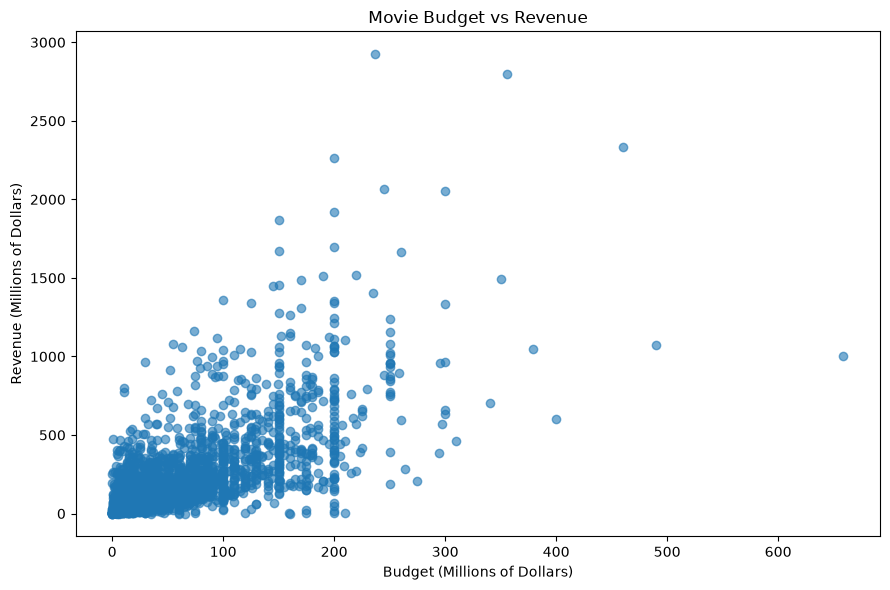

In [7]:
financial_movies = movies.dropna(
    subset=["budget", "revenue"]
)

financial_movies = financial_movies[
    (financial_movies["budget"] > 0) &
    (financial_movies["revenue"] > 0)
]

plt.figure(figsize=(9, 6))

plt.scatter(
    financial_movies["budget"] / 1_000_000,
    financial_movies["revenue"] / 1_000_000,
    alpha=0.6
)

plt.title("Movie Budget vs Revenue")
plt.xlabel("Budget (Millions of Dollars)")
plt.ylabel("Revenue (Millions of Dollars)")
plt.tight_layout()

plt.savefig("../charts/chart_04_budget_vs_revenue.png")
plt.show()

### Insight — Chart 4: Movie Budget vs Revenue

The scatter plot compares movie production budgets with box-office revenue for movies with valid, positive financial values. It helps show whether higher-budget movies generally earn more revenue and highlights films that perform unusually well or poorly relative to their budgets. However, revenue alone does not determine profitability because marketing, distribution, and other costs are not included.

## Chart 5: Number of Movie Releases per Year

**Analysis Type:** Univariate Analysis

This line chart shows how the number of movies represented in the dataset changes across release years. The incomplete year 2026 is excluded from the visualisation to avoid making an incomplete year appear to have unusually low movie output.

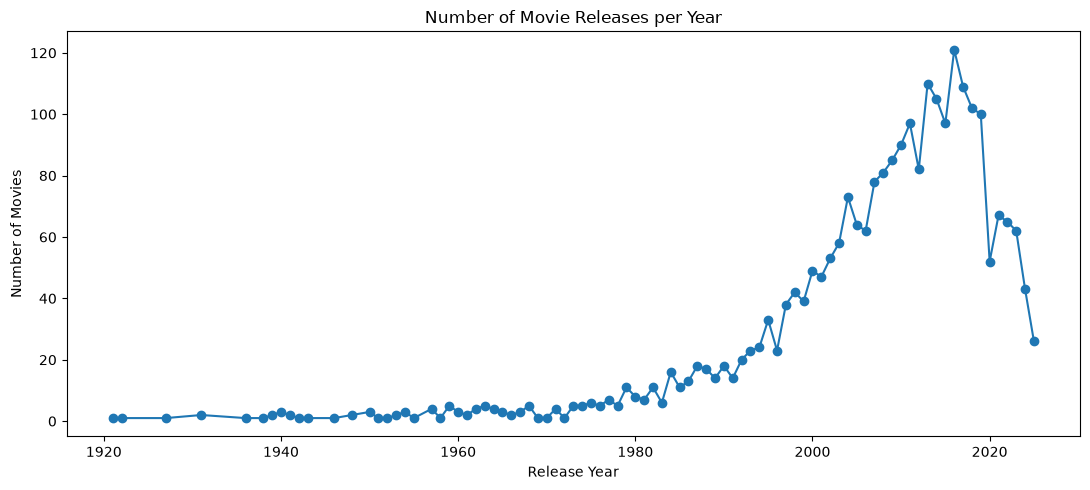

In [8]:
movies["release_date"] = pd.to_datetime(
    movies["release_date"],
    errors="coerce"
)

movies["release_year"] = movies["release_date"].dt.year

yearly_releases = (
    movies.dropna(subset=["release_year"])
    .groupby("release_year")["movie_id"]
    .nunique()
)

# Exclude 2026 because the year is not complete
yearly_releases = yearly_releases[yearly_releases.index < 2026]

plt.figure(figsize=(11, 5))

plt.plot(
    yearly_releases.index,
    yearly_releases.values,
    marker="o"
)

plt.title("Number of Movie Releases per Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")
plt.tight_layout()

plt.savefig("../charts/chart_05_releases_per_year.png")
plt.show()

### Insight — Chart 5: Number of Movie Releases per Year

The chart shows how movie production represented in the dataset changes over time. The number of recorded releases reaches its highest point in 2016, with 121 movies, before declining in more recent years. This decline should be interpreted cautiously because the dataset may contain fewer records for recent years, and 2026 is excluded because it is incomplete.

## Chart 6: Top 10 Actors by Movie Appearances

**Analysis Type:** Univariate Analysis

This bar chart identifies the ten most frequently appearing actors in the dataset based on the number of unique movies in which each actor appears.

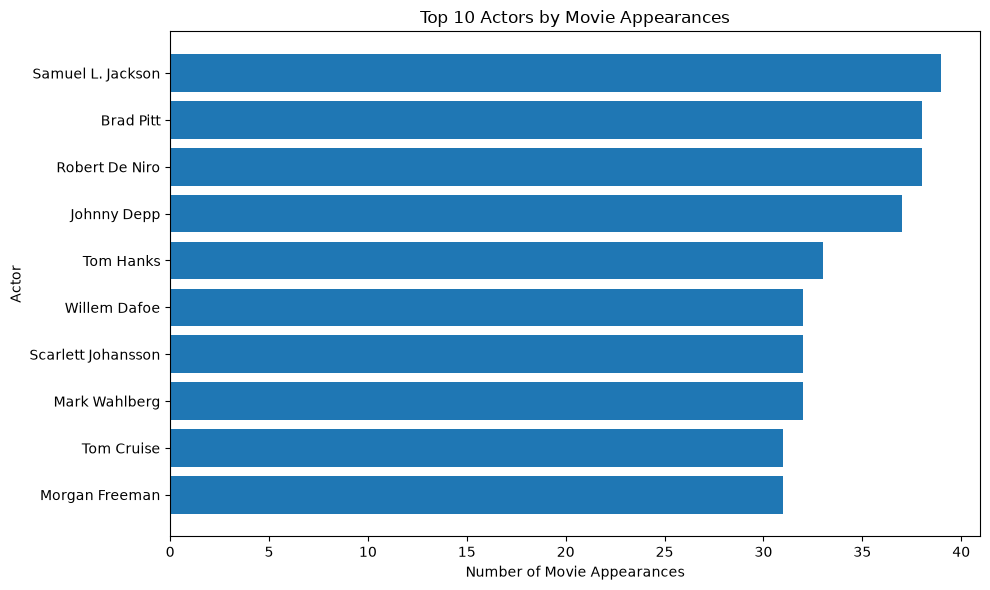

In [9]:
cast = pd.read_csv("../data/cast_cleaned.csv")

actor_counts = (
    cast.groupby("actor_name")["movie_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))

plt.barh(
    actor_counts.index,
    actor_counts.values
)

plt.title("Top 10 Actors by Movie Appearances")
plt.xlabel("Number of Movie Appearances")
plt.ylabel("Actor")
plt.tight_layout()

plt.savefig("../charts/chart_06_top_actors.png")
plt.show()

### Insight — Chart 6: Top 10 Actors by Movie Appearances

Samuel L. Jackson has the highest number of movie appearances in the dataset, followed by Brad Pitt and Robert De Niro. The chart highlights actors with a strong presence across the movies analysed. However, the number of appearances does not necessarily indicate an actor's popularity, lead-role frequency, or commercial success.

## Chart 7: Average Movie Rating by Genre

**Analysis Type:** Bivariate Analysis

This bar chart compares the average audience rating across movie genres. Only genres represented by at least 20 movies are included to reduce the influence of very small genre groups.

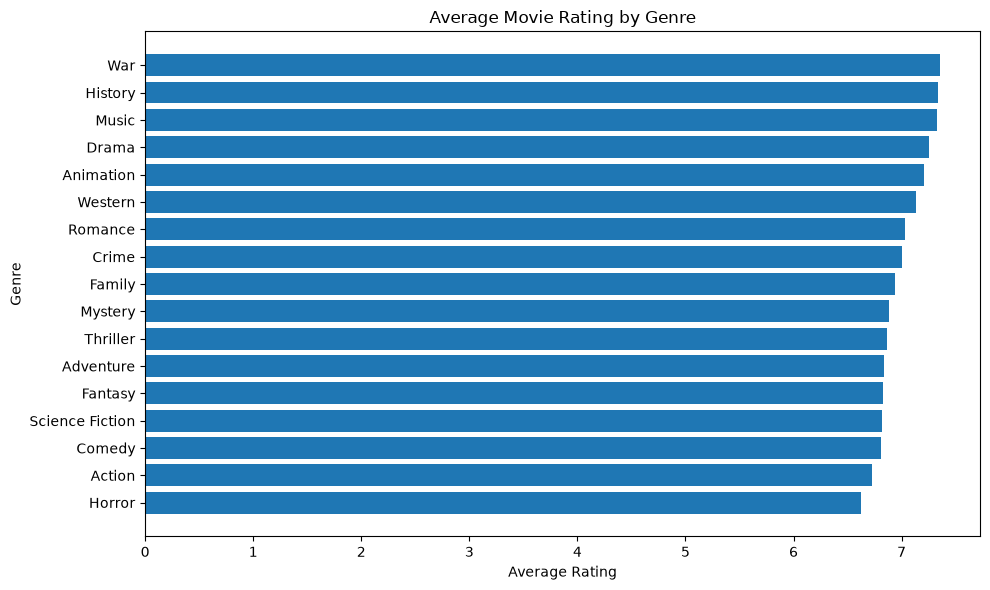

In [10]:
movie_genres = pd.read_csv("../data/movie_genres_cleaned.csv")
genres = pd.read_csv("../data/genres_cleaned.csv")

genre_ratings = movie_genres.merge(
    genres,
    on="genre_id"
)

genre_ratings = genre_ratings.merge(
    movies[["movie_id", "vote_average"]],
    on="movie_id"
)

genre_summary = (
    genre_ratings.groupby("genre_name")
    .agg(
        average_rating=("vote_average", "mean"),
        movie_count=("movie_id", "nunique")
    )
)

# Keep genres linked to at least 20 movies
genre_summary = genre_summary[
    genre_summary["movie_count"] >= 20
].sort_values("average_rating")

plt.figure(figsize=(10, 6))

plt.barh(
    genre_summary.index,
    genre_summary["average_rating"]
)

plt.title("Average Movie Rating by Genre")
plt.xlabel("Average Rating")
plt.ylabel("Genre")
plt.tight_layout()

plt.savefig("../charts/chart_07_rating_by_genre.png")
plt.show()

### Insight — Chart 7: Average Movie Rating by Genre

The chart compares average audience ratings across genres represented by at least 20 movies. War, History, and Music have relatively high average ratings in this dataset, while Horror and Action have lower averages. These differences describe the movies in this sample and do not necessarily mean that every movie in a higher-rated genre is better received than every movie in a lower-rated genre.

## Chart 8: Distribution of Movie Runtimes

**Analysis Type:** Univariate Analysis

This histogram examines the distribution of movie runtimes in minutes across the cleaned dataset and helps identify the most common movie lengths as well as unusually short or long films.

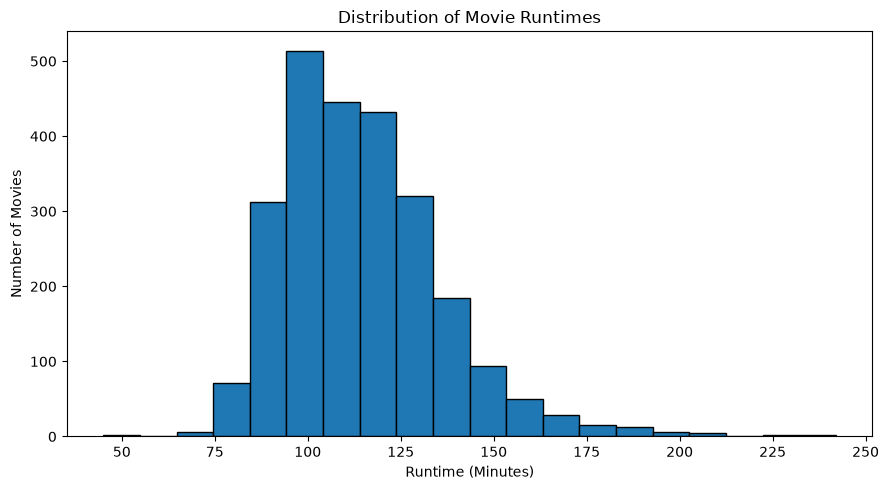

In [11]:
plt.figure(figsize=(9, 5))

plt.hist(
    movies["runtime"].dropna(),
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Movie Runtimes")
plt.xlabel("Runtime (Minutes)")
plt.ylabel("Number of Movies")
plt.tight_layout()

plt.savefig("../charts/chart_08_runtime_distribution.png")
plt.show()

### Insight — Chart 8: Distribution of Movie Runtimes

The histogram shows the distribution of movie lengths in minutes. The average runtime in the dataset is approximately 114 minutes, suggesting that many films are around two hours long. A small number of unusually short or long movies appear at the extremes, and these should be investigated rather than automatically treated as data errors.

## Chart 9: Movie Popularity vs Vote Count

**Analysis Type:** Bivariate Analysis

This scatter plot examines the relationship between the number of audience votes a movie has received and its TMDB popularity score. It helps identify the general relationship between these variables as well as movies that do not follow the overall pattern.

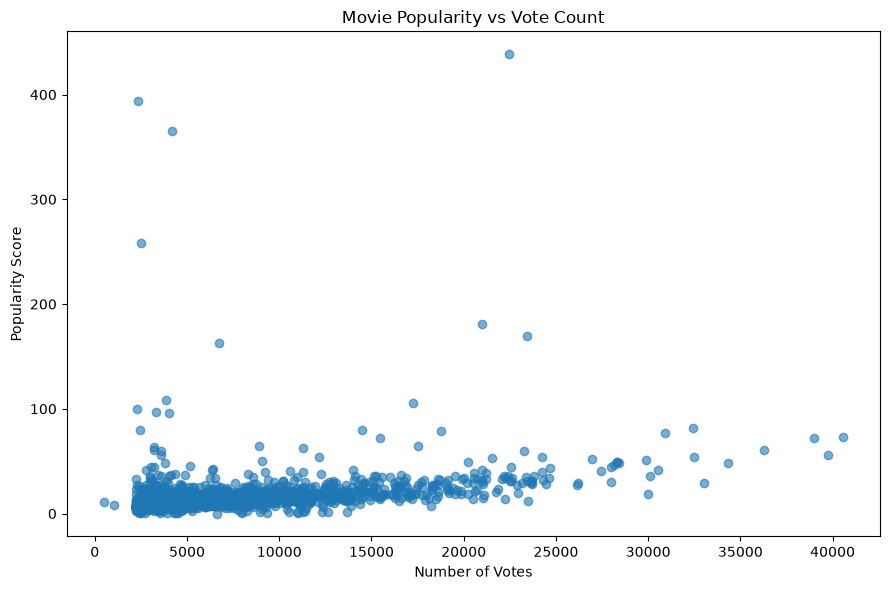

In [12]:
plt.figure(figsize=(9, 6))

plt.scatter(
    movies["vote_count"],
    movies["popularity"],
    alpha=0.6
)

plt.title("Movie Popularity vs Vote Count")
plt.xlabel("Number of Votes")
plt.ylabel("Popularity Score")
plt.tight_layout()

plt.savefig("../charts/chart_09_popularity_vs_votes.png")
plt.show()

### Insight — Chart 9: Movie Popularity vs Vote Count

The scatter plot shows a positive relationship between vote count and movie popularity, consistent with the calculated correlation of 0.36. However, the points are widely spread, indicating that vote count alone does not explain popularity. Some movies achieve high popularity despite receiving fewer votes, potentially reflecting recent releases or temporary audience interest.

## Chart 10: Top 10 Most Frequent Movie Keywords

**Analysis Type:** Univariate Analysis

This bar chart identifies the ten most frequently occurring keywords in the movie dataset. It highlights common themes, content characteristics, and tagging patterns across the movies analysed.

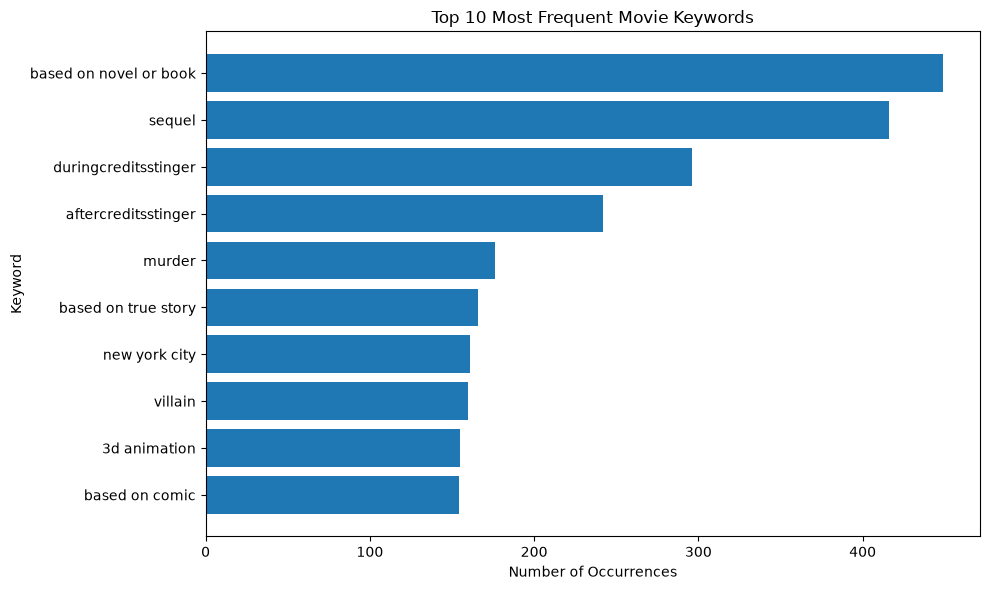

In [13]:
keywords = pd.read_csv("../data/movie_keywords_cleaned.csv")

top_keywords = (
    keywords["keyword_name"]
    .value_counts()
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_keywords.index,
    top_keywords.values
)

plt.title("Top 10 Most Frequent Movie Keywords")
plt.xlabel("Number of Occurrences")
plt.ylabel("Keyword")
plt.tight_layout()

plt.savefig("../charts/chart_10_top_keywords.png")
plt.show()

### Insight — Chart 10: Top 10 Most Frequent Movie Keywords

The keyword “based on novel or book” appears most frequently in the dataset, followed by “sequel” and “duringcreditsstinger”. This suggests that adaptations and franchise-related content are prominent among the movies analysed. However, keyword frequency reflects how the dataset is tagged and does not directly measure a movie's popularity or success.

## Plotly Bivariate Analysis: Movie Budget vs Revenue

**Analysis Type:** Bivariate Analysis

This interactive Plotly scatter plot examines the relationship between movie production budget and worldwide revenue. Only movies with positive budget and revenue values are included, and the interactive hover feature allows individual movie titles to be explored.

In [3]:
# BIVARIATE ANALYSIS USING PLOTLY
# Relationship between movie budget and revenue

plot_data = movies[
    (movies["budget"] > 0) &
    (movies["revenue"] > 0)
].copy()

fig = px.scatter(
    plot_data,
    x="budget",
    y="revenue",
    hover_name="title",
    title="Movie Budget vs Revenue"
)

fig.update_layout(
    xaxis_title="Budget ($)",
    yaxis_title="Revenue ($)"
)

fig.show()

### Insight — Plotly Bivariate Analysis

The interactive scatter plot shows a general positive relationship between movie budget and worldwide revenue, although there is considerable variation between individual films. Some movies generate substantially higher revenue relative to their production budgets, while a large budget does not guarantee equally high revenue. The interactive hover feature makes it possible to examine individual movies within this overall pattern.

## Seaborn Multivariate Analysis: Correlation Heatmap

**Analysis Type:** Multivariate Analysis

This correlation heatmap examines the relationships among runtime, budget, revenue, popularity, average rating and vote count. Zero budget and revenue values are treated as missing because they represent unknown financial information in the dataset.

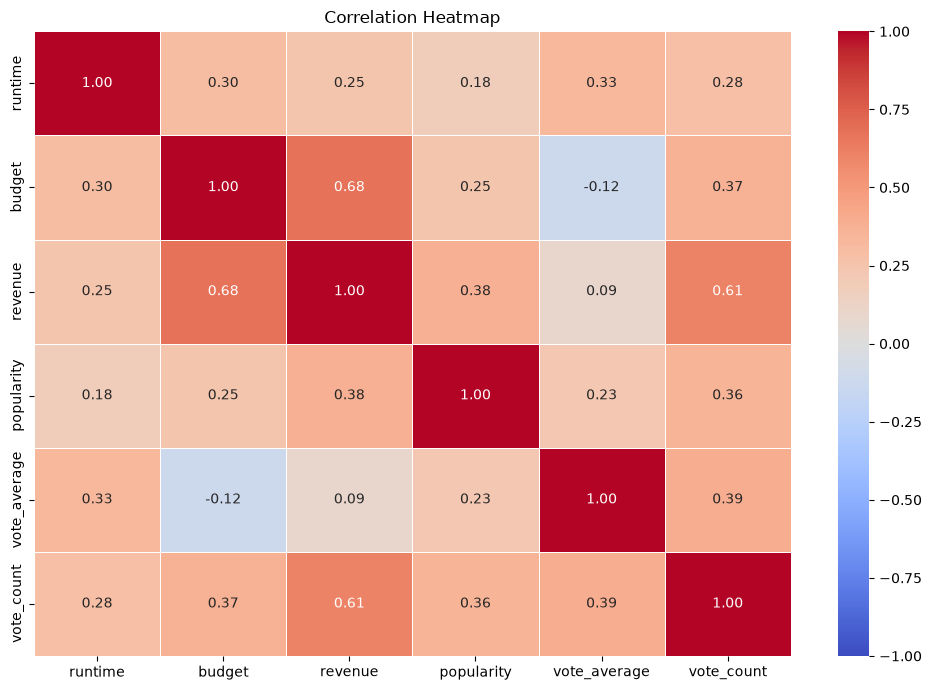

In [ ]:
# MULTIVARIATE ANALYSIS USING SEABORN
# Correlation between key movie variables

multivariate_data = movies[
    [
        "runtime",
        "budget",
        "revenue",
        "popularity",
        "vote_average",
        "vote_count"
    ]
].copy()

# Treat zero budget and revenue as missing values
multivariate_data["budget"] = multivariate_data["budget"].replace(
    0,
    float("nan")
)

multivariate_data["revenue"] = multivariate_data["revenue"].replace(
    0,
    float("nan")
)

# Remove rows with missing values
multivariate_data = multivariate_data.dropna()

# Calculate correlation matrix
correlation_matrix = multivariate_data.corr()

# Create heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

### Insight — Multivariate Correlation Analysis

The correlation heatmap shows that budget and revenue have the strongest positive relationship (0.68), suggesting that higher-budget movies tend to generate higher revenue. Revenue also has a moderately strong positive relationship with vote count (0.61), indicating that commercially successful movies often receive greater audience engagement. In contrast, budget has a weak negative correlation with average rating (-0.12), showing that a larger production budget does not necessarily result in better audience ratings. Overall, financial success, popularity and audience ratings represent different aspects of movie performance and should be considered together.

## Business Insights and Recommendations

The exploratory analysis of the TMDB movie dataset highlights several patterns that can support decision-making in the film industry.

### Key Insights

- Movie budget and revenue show a positive relationship, suggesting that higher investment can be associated with greater revenue potential. However, a high budget alone does not guarantee financial success.
- Popularity and audience engagement provide useful indicators of movie performance, but they should be considered together with financial and rating information.
- Genre analysis shows that audience popularity and average ratings vary across different movie genres, suggesting that genre is an important factor to consider when analysing movie performance.
- Movie ratings alone should not be treated as a measure of financial success because highly rated films do not necessarily generate the highest revenue.
- Historical release patterns show substantial growth in the number of movies represented in the dataset over time.

### Business Recommendations

1. **Evaluate investment risk:** Production companies should assess budget alongside expected revenue, genre, popularity and audience demand rather than assuming that a larger production budget will automatically produce higher returns.

2. **Use multiple performance indicators:** Decisions should combine financial measures, popularity, ratings and audience engagement instead of relying on a single metric.

3. **Consider genre performance:** Studios and investors can use historical genre-level performance as one input when evaluating future movie projects.

4. **Monitor audience engagement:** Popularity and voting activity can provide useful signals of audience interest and may support marketing and distribution decisions.

5. **Use data-driven decision making:** Historical movie data can support production, marketing and investment planning, while recognising that past performance does not guarantee future success.